# Coastline extraction
Extracting coastline data for the Barwon river mouth from Landsat data

In [2]:
import os
import glob
import warnings
from zipfile import *

import arcgis
from arcgis import GIS
from arcgis.geometry import Point, buffer
from arcgis.features import FeatureSet
import arcpy
from arcpy.management import PolygonToLine
from datetime import datetime
import pandas as pd
from arcgis.features import GeoAccessor, GeoSeriesAccessor
from arcgis.raster.analytics import convert_raster_to_feature
from arcgis.features.manage_data import overlay_layers
from arcgis.raster.functions import equal_to, greater_than, greater_than_equal, clip, apply, extract_band, stretch

BARWON_HEADS = (144.49, -38.27)
WGS84 = 4326
WEBMERCATOR = 3857
WEBMERCATOR_LATEST = 102100
M_ESRI = 9001

In [3]:
gis = GIS("home")
gis2 = GIS('https://sabastianbouma.maps.arcgis.com', 'sabastianbouma', '18OceanGroveE2ab6214')

<Item title:"Multispectral Landsat" type:Imagery Layer owner:esri_imagery>
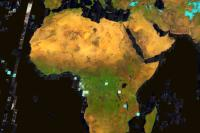

In [4]:
landsat_item = gis.content.get('d9b466d6a9e647ce8d1dd5fe12eb434b')
landsat = landsat_item.layers[0]
landsat_item

In [ ]:
def make_aoi_buffer_fs(lon, lat, radius_m, out_wkid=WEBMERCATOR, gis=None):
    """Circular AOI of radius_m metres around a lon/lat point."""
    pt = Point({"x": lon, "y": lat, "spatialReference": {"wkid": WGS84}})
    geom = buffer(
        [pt],
        in_sr=WGS84,
        distances=[radius_m],
        unit=M_ESRI,
        out_sr=out_wkid,
        geodesic=True,
        gis=gis,
    )
    return geom[0]

def make_aoi_fs(geom, out_wkid=WEBMERCATOR):
    """AOI FeatureSet from an Esri polygon geometry dict."""
    fs = FeatureSet.from_dict({
        "geometryType": "esriGeometryPolygon",
        "spatialReference": {"wkid": out_wkid},
        "fields": [{"name": "Name", "type": "esriFieldTypeString", "alias": "Name"}],
        "features": [{"attributes": {"Name": "AOI"}, "geometry": geom}]
    })
    return fs

buffer_dist = 5000  # metres

aoi_geom = make_aoi_buffer_fs(*BARWON_HEADS, radius_m=buffer_dist, gis=gis)
aoi = make_aoi_fs(aoi_geom)
m = gis.map('Barwon Heads, Victoria, Australia')
m.content.add(aoi)

def extent_from_geometry(geom, pad=0.05, wkid=WEBMERCATOR_LATEST, latest_wkid=WEBMERCATOR):
    """Padded extent dict (same format as the tutorial) from an Esri polygon with 'rings'."""
    xs = [pt[0] for ring in geom["rings"] for pt in ring]
    ys = [pt[1] for ring in geom["rings"] for pt in ring]
    dx = (max(xs) - min(xs)) * pad
    dy = (max(ys) - min(ys)) * pad
    return {
        "spatialReference": {"latestWkid": latest_wkid, "wkid": wkid},
        "xmin": min(xs) - dx,
        "ymin": min(ys) - dy,
        "xmax": max(xs) + dx,
        "ymax": max(ys) + dy,
    }

extent = extent_from_geometry(aoi_geom)  # 10% padding so the circle isn't touching the edge

m.extent = extent
m

Map()

In [6]:
import pandas as pd
from datetime import datetime
selected = landsat.filter_by(where="(Category = 1) and (CloudCover<0.1)",
                             time=[datetime(2014, 1, 1), datetime(2026, 12, 31)],
                             geometry=arcgis.geometry.filters.intersects(aoi_geom))

df = selected.query(out_fields="AcquisitionDate, GroupName, CloudCover, DayOfYear", 
                    order_by_fields="AcquisitionDate").sdf
df['AcquisitionDate'] = pd.to_datetime(df['AcquisitionDate'], unit='ms')
oid = df["OBJECTID"].tolist()
df

,OBJECTID,AcquisitionDate,GroupName,CloudCover,DayOfYear,SHAPE
0,1195269,2014-02-06 00:10:38,LC08_L1TP_093086_20140206_20200912_02_T1_MTL,0.0417,86,"{""rings"": [[[16210522.877700001, -4414823.3535..."
1,1195291,2014-02-06 00:11:02,LC08_L1TP_093087_20140206_20200912_02_T1_MTL,0.0005,87,"{""rings"": [[[16165377.744499996, -4616127.2491..."
2,1195283,2014-10-04 00:09:49,LC08_L1TP_093086_20141004_20200910_02_T1_MTL,0.0517,86,"{""rings"": [[[16209250.009000003, -4414969.9182..."
3,1195305,2014-10-04 00:10:13,LC08_L1TP_093087_20141004_20200910_02_T1_MTL,0.0705,87,"{""rings"": [[[16164012.837700002, -4616338.9985..."
4,1195284,2014-10-20 00:09:52,LC08_L1TP_093086_20141020_20200910_02_T1_MTL,0.0015,86,"{""rings"": [[[16186887.690399997, -4509702.3372..."
...,...,...,...,...,...,...
91,5853678,2026-02-23 00:09:39,LC08_L1TP_093086_20260223_20260227_02_T1_MTL,0.0902,86,"{""rings"": [[[16211916.682400003, -4415782.8213..."
92,5880037,2026-03-19 00:09:57,LC09_L1GT_093087_20260319_20260319_02_T2_MTL,0.0971,87,"{""rings"": [[[16168056.564400002, -4616466.1259..."
93,5913902,2026-05-22 00:08:57,LC09_L1TP_093086_20260522_20260522_02_T1_MTL,0.0812,86,"{""rings"": [[[16213194.419600002, -4415211.2967..."
94,5935175,2026-09-11 00:09:36,LC09_L1TP_093086_20260911_20260911_02_T1_MTL,0.01,86,"{""rings"": [[[16208926.185000002, -4415355.0007..."


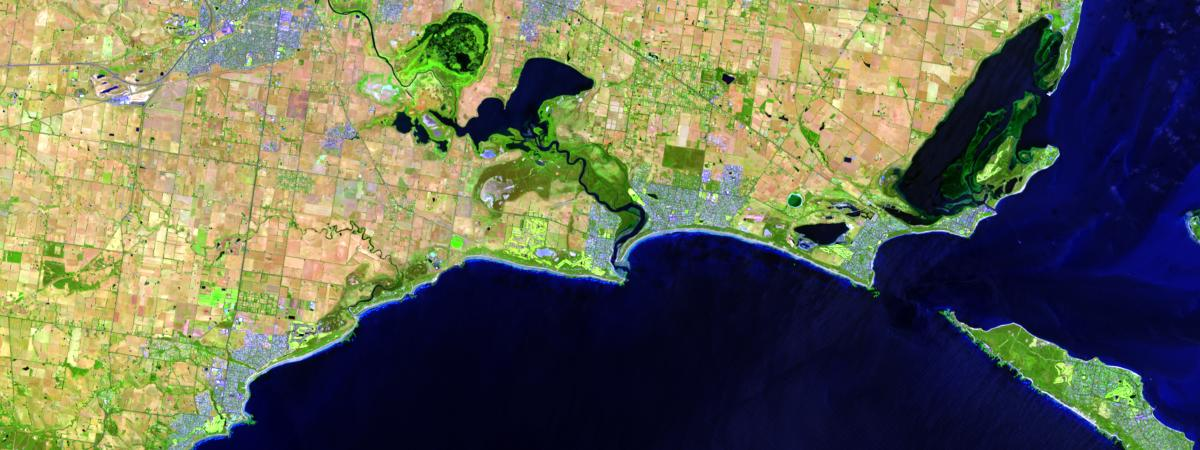

In [7]:
landsat.mosaic_by(method='lock_rasters', lock_rasters=oid)
landsat.extent = m.extent
landsat

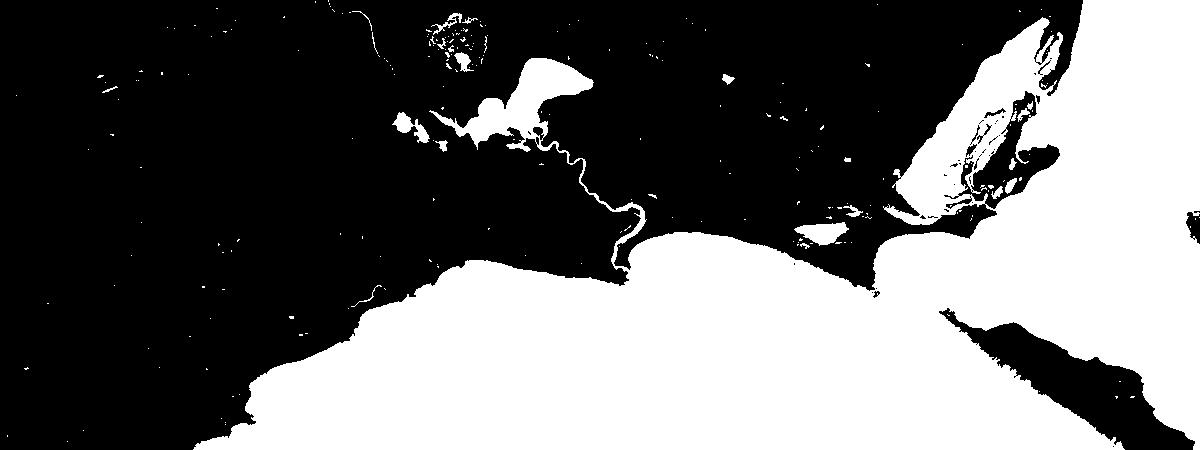

In [8]:
nir1 = extract_band(landsat, [5])
blue1 = extract_band(landsat, [2])
red1 = extract_band(landsat, [4])

binary1 = arcgis.raster.functions.raster_calculator([nir1, blue1, red1],  
                                                    ['nir', 'blue', 'red'],
                                                    "(blue>nir)&(blue>red)", 
                                                    extent_type='FirstOf', 
                                                    cellsize_type='FirstOf')
dra1 = arcgis.raster.functions.stretch(binary1, 
                                      stretch_type='MinMax', 
                                      dra=True)
dra1

In [12]:
clip_diff1 = clip(dra1, aoi_geom)
water_ras = greater_than([clip_diff1, 0], extent_type='FirstOf', cellsize_type='FirstOf')
warnings.filterwarnings("ignore", message="Unverified HTTPS request")
water_raster = water_ras.save('water_ras'+str(datetime.now().microsecond), gis=gis2)
# dra2 = arcgis.raster.functions.stretch(water_ras, 
#                                       stretch_type='MinMax', 
#                                       dra=True)
# dra2
dra2 = arcgis.raster.functions.stretch(water_ras, 
                                      stretch_type='MinMax', 
                                      dra=True)
dra2_ras = dra2.save("dra_raster"+str(datetime.now().microsecond), gis=gis2)
dra2

{"messageCode": "RA_120001", "message": "GenerateRaster failed."}
{"messageCode": "RA_120306", "message": "Cause of failure: A raster error has occurred. The messages that follow will provide more detail.", "params": {"cause": "A raster error has occurred. The messages that follow will provide more detail."}}
{"messageCode": "RA_120306", "message": "Cause of failure: VSISync, Path: C:\\Users\\arcgis\\AppData\\Local\\ESRI\\Local Caches\\MapCacheV1\\_cloudStores_O0pc3Cgh42dMvFvZ_3860596141174b9090adeeafcc919634\\water_ras652286.crf\\conf.json].", "params": {"cause": "VSISync, Path: C:\\Users\\arcgis\\AppData\\Local\\ESRI\\Local Caches\\MapCacheV1\\_cloudStores_O0pc3Cgh42dMvFvZ_3860596141174b9090adeeafcc919634\\water_ras652286.crf\\conf.json]"}}
{"messageCode": "RA_120306", "message": "Cause of failure: 404 [Failed cloud operation: Open, Path: /vsiaz/o0pc3cgh42dmvfvz/3860596141174b9090adeeafcc919634/water_ras652286.crf].", "params": {"cause": "404 [Failed cloud operation: Open, Path: /vsi

Exception: Job failed: [{'type': 'esriJobMessageTypeInformative', 'description': 'Submitted.'}, {'type': 'esriJobMessageTypeInformative', 'description': 'Executing...'}, {'type': 'esriJobMessageTypeInformative', 'description': 'Start Time: Tuesday, November 3, 2026 2:03:29 AM'}, {'type': 'esriJobMessageTypeInformative', 'description': 'Raster Analysis Privilege Check: OK'}, {'type': 'esriJobMessageTypeInformative', 'description': 'Output item id is: 3860596141174b9090adeeafcc919634'}, {'type': 'esriJobMessageTypeInformative', 'description': 'Output image service url is: https://tiledimageservices8.arcgis.com/O0pc3Cgh42dMvFvZ/arcgis/rest/services/water_ras652286/ImageServer'}, {'type': 'esriJobMessageTypeInformative', 'description': 'Output cloud raster name is: /cloudStores/O0pc3Cgh42dMvFvZ/3860596141174b9090adeeafcc919634/water_ras652286.crf'}, {'type': 'esriJobMessageTypeInformative', 'description': '{"rasterFunction": "Local", "rasterFunctionArguments": {"Rasters": [{"rasterFunction

In [12]:
## Create dataframe from feature layer and get water polygons
dfm1 = dra2.query().sdf
water_poly = gis2.content.import_data(dfm1, title='coast_poly_full'+str(datetime.now().microsecond))

In [81]:
water_poly.layers[0].query().sdf

,OBJECTID,name,min_ps,max_ps,low_ps,high_ps,category,group_name,product_name,center_x,...,pr,latest,day_of_year,month,landsat_scene_id,landsat_product_id,dataset_id,Shape__Area,Shape__Length,SHAPE
0,1,L5001055_05520070505_MS,0.0,300.0,30.0,120.0,1,L5001055_05520070505,L1T,-7030153.451637,...,1055,999055,125,5,,,GLS-2005,33001819439.278809,727816.980388,"{""rings"": [[[-6918459.9775, 879441.755399998],..."
1,2,L5001056_05620050312_MS,0.0,300.0,30.0,120.0,1,L5001056_05620050312,L1T,-7055681.0224,...,1056,999056,71,3,,,GLS-2005,32638843731.085693,723623.708204,"{""rings"": [[[-6945276.0207, 717969.792599998],..."
2,3,L5001060_06020040901_MS,0.0,300.0,30.0,120.0,1,L5001060_06020040901,L1T,-7189513.259191,...,1060,999060,245,9,,,GLS-2005,32295750801.570068,719785.258357,"{""rings"": [[[-7079957.4065, 71486.3106999993],..."
3,4,L5001061_06120070724_MS,0.0,300.0,30.0,120.0,1,L5001061_06120070724,L1T,-7221374.215069,...,1061,999061,205,7,,,GLS-2005,32461703155.405762,721695.102525,"{""rings"": [[[-7111404.4816, -90268.0909000002]..."
4,5,L5001062_06220050904_MS,0.0,300.0,30.0,120.0,1,L5001062_06220050904,L1T,-7264994.790343,...,1062,999062,247,9,,,GLS-2005,32558541924.522217,722827.890306,"{""rings"": [[[-7154710.4247, -249518.3343], [-7..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,996,L5123020_02020070715_MS,0.0,300.0,30.0,120.0,1,L5123020_02020070715,L1T,13779749.982623,...,123020,877020,196,7,,,GLS-2005,110300310512.734375,1329689.125676,"{""rings"": [[[13995872.7199, 7928560.7479], [13..."
996,997,L5123021_02120060728_MS,0.0,300.0,30.0,120.0,1,L5123021_02120060728,L1T,13699254.956827,...,123021,877021,209,7,,,GLS-2005,102397862199.21875,1281154.094481,"{""rings"": [[[13906707.8069, 7644230.9566], [13..."
997,998,L5123026_02620060712_MS,0.0,300.0,30.0,120.0,1,L5123026_02620060712,L1T,13332529.208574,...,123026,877026,193,7,,,GLS-2005,74409888630.539062,1092199.068205,"{""rings"": [[[13506166.3406, 6345778.6669], [13..."
998,999,L5123028_02820060728_MS,0.0,300.0,30.0,120.0,1,L5123028_02820060728,L1T,13210258.90473,...,123028,877028,209,7,,,GLS-2005,66628900525.804688,1033479.030154,"{""rings"": [[[13373337.466, 5877761.5128], [133..."


In [13]:
## Get the polygon with largest area as it will represent the coastline
df = water_poly.layers[0].query().sdf
df['MYAREA'] = df.SHAPE.geom.area
dfm5 = df[df['MYAREA']==df['MYAREA'].max()]
coast_poly = gis2.content.import_data(dfm5, title='coast_poly'+str(datetime.now().microsecond))

In [14]:
dc_df = pd.DataFrame.spatial.from_layer(coast_poly.layers[0])
display(dc_df.head())

,OBJECTID,name,min_ps,max_ps,low_ps,high_ps,category,group_name,product_name,center_x,...,latest,day_of_year,month,landsat_scene_id,landsat_product_id,dataset_id,myarea,Shape__Area,Shape__Length,SHAPE
0,1,L5048014_01420060916_MS,0.0,300.0,30.0,120.0,1,L5048014_01420060916,L1T,-12714078.868969,...,1952014,259,9,,,GLS-2005,190259237120.859711,190259237120.851562,1747032.007826,"{""rings"": [[[-12418362.0167, 9874343.5698], [-..."


In [17]:
# Create empty dataframe
df = pd.DataFrame()

# Create polyline
df['SHAPE'] = dc_df.SHAPE.geom.boundary()
# coast_polyline = df.spatial.to_featurelayer('coastline_polyline'+str(datetime.now().microsecond))
#Create a mask
mask = greater_than_equal([clip_diff1, -1], extent_type='FirstOf', cellsize_type='FirstOf')
# mask_ras = mask.save('mask'+str(datetime.now().microsecond), gis=gis2)

# Create a mask to remove noise which covers whole extent of clipped raster
aoi2 = convert_raster_to_feature(mask, 
                                field='Value', 
                                output_type='Polygon', 
                                simplify=True, 
                                output_name='aoi2'+str(datetime.now().microsecond), 
                                gis=gis2)

c:\Program Files\ArcGIS\Pro\bin\Python\envs\arcgispro-py3\Lib\site-packages\urllib3\connectionpool.py:1097: InsecureRequestWarning: Unverified HTTPS request is being made to host 'rasteranalysis8.arcgis.com'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#tls-warnings
  warnings.warn(
c:\Program Files\ArcGIS\Pro\bin\Python\envs\arcgispro-py3\Lib\site-packages\urllib3\connectionpool.py:1097: InsecureRequestWarning: Unverified HTTPS request is being made to host 'rasteranalysis8.arcgis.com'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#tls-warnings
  warnings.warn(
c:\Program Files\ArcGIS\Pro\bin\Python\envs\arcgispro-py3\Lib\site-packages\urllib3\connectionpool.py:1097: InsecureRequestWarning: Unverified HTTPS request is being made to host 'rasteranalysis8.arcgis.com'. Adding certificate verification is strongly advised. See: https://urllib3.r

In [ ]:
### Create neg_buffer to remove the noise
neg_buffer = arcgis.create_buffers(aoi2, 
                                   distances=[-10],
                                   units='Meters', 
                                   output_name='aoi_neg_buf'+str(datetime.now().microsecond), 
                                   gis=gis2)

In [ ]:
coastline_final = overlay_layers(coast_polyline.layers[0], neg_buffer.layers[0], output_name='extracted_coastline'+str(datetime.now().microsecond))
